# Gradient Descent Step by Step: Finding the Intercept

## What Are We Doing in This Notebook?

This notebook demonstrates how **gradient descent minimizes the mean squared error (MSE)** for a simple linear-regression line, and compares the result visually with an ordinary least-squares (OLS) reference.

1. Generate and plot 10 noisy, one-feature data points.
2. Fit an OLS regression line to provide a reference.
3. Keep the slope fixed at $m=78.35$ and use gradient descent to adjust only the intercept $b$.
4. Calculate the MSE gradient from all observations, update $b$, and visualize the line after each update.
5. Run repeated updates from another starting intercept to illustrate how the line moves toward the minimum-loss intercept.

**Important scope:** this walkthrough does not use gradient descent to learn both slope and intercept. It holds $m$ fixed and optimizes only $b$. The final loop starts at $b=-100$ and uses a different learning rate to show repeated updates. OLS is a comparison reference; finite gradient-descent updates may approach, but are not guaranteed to exactly reproduce, the OLS line. With the slope fixed, MSE is a convex quadratic function of $b$, so its minimum is global rather than merely local.

---


## 1. Definition

**Gradient descent** is an iterative optimization algorithm for minimizing a differentiable objective (or loss) function. At each iteration, it calculates the gradient—the direction of steepest increase—and moves the parameters in the opposite direction. Repeating this update can move the parameters toward a minimum of the loss.

For parameters collected in a vector $\boldsymbol{\theta}$, the general update is

$$
\boldsymbol{\theta}^{(t+1)} = \boldsymbol{\theta}^{(t)} - \eta\,\nabla_{\boldsymbol{\theta}} J\!\left(\boldsymbol{\theta}^{(t)}\right),
$$

where $t$ is the iteration number, $J$ is the objective function, $\nabla_{\boldsymbol{\theta}}J$ is its gradient, and $\eta > 0$ is the learning rate (step size).

## 2. The problem in this notebook

The data contain $n=10$ observations $(x_i,y_i)$. We use the linear model

$$
\hat y_i = m x_i + b,
$$

but **hold the slope fixed** at $m=78.35$ and optimize only the intercept $b$. The starting intercept is $b^{(0)}=0$. Thus, every iteration changes $b$ but leaves $m$ unchanged. This is batch gradient descent because each update uses all 10 observations.

Define the residual for observation $i$ at iteration $t$ as

$$
r_i^{(t)} = y_i - \hat y_i^{(t)} = y_i - (m x_i + b^{(t)}).
$$

We minimize the **mean squared error (MSE)**:

$$
J(b) = \operatorname{MSE}(b) = \frac{1}{n}\sum_{i=1}^{n}\left[y_i-(m x_i+b)\right]^2 = \frac{1}{n}\sum_{i=1}^{n}\left(r_i\right)^2.
$$

## 3. Derive the gradient with respect to the intercept

Because $m$ and each $x_i$ are fixed, $\partial (m x_i+b)/\partial b=1$. Applying the chain rule to each squared residual gives

$$
\begin{aligned}
\frac{\partial J}{\partial b}
&= \frac{1}{n}\sum_{i=1}^{n} 2\left[y_i-(m x_i+b)\right]\frac{\partial}{\partial b}\left[y_i-(m x_i+b)\right] \\
&= \frac{1}{n}\sum_{i=1}^{n} 2\left[y_i-(m x_i+b)\right](-1) \\
&= -\frac{2}{n}\sum_{i=1}^{n}\left[y_i-(m x_i+b)\right] \\
&= \frac{2}{n}\sum_{i=1}^{n}(m x_i+b-y_i).
\end{aligned}
$$

The negative sign is important: when the predictions are, on average, too low, the residuals are positive, the gradient is negative, and subtracting that gradient increases $b$.

## 4. Derive the update rule

Substitute the derivative into the gradient-descent update $b^{(t+1)}=b^{(t)}-\eta\,\partial J/\partial b$:

$$
\boxed{
b^{(t+1)} = b^{(t)} + \frac{2\eta}{n}\sum_{i=1}^{n}\left[y_i-(m x_i+b^{(t)})\right]
}
$$

For this example, $n=10$, $m=78.35$, $b^{(0)}=0$, and the learning rate is $\eta=0.1$:

1. **Predict:** $\hat y_i^{(0)}=78.35x_i+0$ for every observation.
2. **Calculate residuals:** $r_i^{(0)}=y_i-78.35x_i$.
3. **Calculate the gradient:** $g^{(0)}=-(2/10)\sum_{i=1}^{10}r_i^{(0)}$.
4. **Update the intercept:** $b^{(1)}=0-0.1g^{(0)}=0.02\sum_{i=1}^{10}r_i^{(0)}$.
5. **Repeat:** recalculate predictions and residuals using $b^{(1)}$, then apply the same derivative and update to obtain $b^{(2)}$.

In the code, `gradient_b` is $\partial J/\partial b$; it is not the slope $m$. The slope remains fixed at 78.35.

## 5. Why the updates approach the best intercept

For a fixed slope, set the derivative to zero to find the intercept that minimizes this convex quadratic loss:

$$
-\frac{2}{n}\sum_{i=1}^{n}\left[y_i-(m x_i+b^*)\right]=0
\quad\Longrightarrow\quad
\boxed{b^*=\frac{1}{n}\sum_{i=1}^{n}(y_i-m x_i)}.
$$

This gives a useful check: at the minimizing intercept, the mean residual is zero. Gradient descent approaches this value iteratively rather than calculating it directly. Since the MSE is a convex quadratic in $b$, there is one global minimum for this fixed-slope problem.

The derivative can also be written as $\partial J/\partial b=2(b-b^*)$. Therefore, the update satisfies

$$
b^{(t+1)}-b^*=(1-2\eta)(b^{(t)}-b^*).
$$

For this one-parameter MSE problem, updates converge when $0<\eta<1$; a smaller learning rate usually takes more iterations. Here, $\eta=0.1$ multiplies the remaining distance to the optimum by $0.8$ per iteration. A rate that is too large can cause overshooting or divergence.

> **Normalization matters:** this notebook uses the mean squared error, so its derivative includes $1/n$. If instead the loss were the sum of squared errors (SSE), the derivative would be $-2\sum_i r_i$—$n$ times larger—and the same numerical learning rate would produce a different, potentially unstable update. Keep the loss definition and gradient formula consistent.

## 6. Theory and reading notes

- **Gradient:** the derivative (or, with many parameters, vector of partial derivatives) tells how the loss changes as a parameter changes. Its sign indicates which direction increases the loss; the update moves in the opposite direction.
- **Learning rate $\eta$:** controls the update size. Too small means slow progress; too large can jump across the minimum or fail to converge.
- **Iteration / epoch:** one update here is one iteration and uses the full dataset. In this simple setting, one full pass over the 10 observations is also one epoch.
- **Fixed versus learned parameters:** this walkthrough learns only $b$. To learn both $m$ and $b$, calculate both partial derivatives and update both parameters; this notebook's formula does not do that.
- **Gradient descent versus ordinary least squares:** ordinary least squares can solve linear regression directly for its coefficients. Gradient descent instead repeatedly updates parameters and is useful for optimization problems where a direct solution is inconvenient.
- **The later loop:** the final code example resets $b$ to $-100$ to show repeated updates from a different starting point; it uses the same MSE gradient and fixed slope.

## Summary

| Item | Meaning or formula | Used here |
|---|---|---|
| Prediction | $\hat y_i=m x_i+b$ | $m=78.35$ is fixed; $b$ is optimized |
| Residual | $r_i=y_i-\hat y_i$ | Difference between observed and predicted values |
| Objective | $J(b)=\frac{1}{n}\sum_i r_i^2$ | Mean squared error over all 10 observations |
| Gradient | $\frac{\partial J}{\partial b}=-\frac{2}{n}\sum_i r_i$ | Derivative of MSE with respect to the intercept |
| Update | $b^{(t+1)}=b^{(t)}-\eta\frac{\partial J}{\partial b}$ | Move opposite the gradient; start at $b^{(0)}=0$ |
| Best fixed-slope intercept | $b^*=\frac{1}{n}\sum_i(y_i-m x_i)$ | The intercept where the mean residual is zero |
| Learning rate | $0<\eta<1$ for this one-parameter MSE example | $\eta=0.1$; smaller values converge more slowly |

### Step 1 — Import the tools

Import `make_regression` to generate a small example dataset and NumPy for numerical calculations used in the gradient and parameter updates.

In [1]:
from sklearn.datasets import make_regression
import numpy as np

### Step 2 — Generate sample data

Create 10 one-feature regression observations. The fixed `random_state` makes the synthetic data reproducible; `noise=80` adds variation around the underlying linear relationship.

In [2]:
X,y = make_regression(n_samples=10, n_features=1, n_informative=1, n_targets=1, noise=80, random_state=13)

### Step 3 — Inspect the data

Plot each input value against its target. This scatter plot helps us see the relationship and spread before fitting a line.

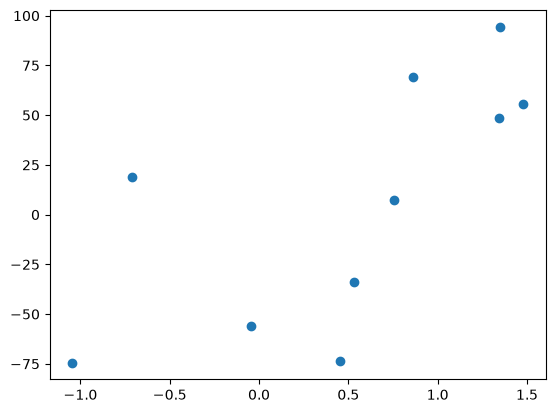

In [3]:
import matplotlib.pyplot as plt
plt.scatter(X,y)

### Step 4 — Import the reference model

Import scikit-learn's `LinearRegression`. We use ordinary least squares (OLS) as a reference line to compare against our gradient-descent estimates.

In [4]:
# Lets Apply OLS
from sklearn.linear_model import LinearRegression

### Step 5 — Create the OLS model

Instantiate the linear-regression estimator. It has not yet learned coefficients from the data.

In [5]:
reg = LinearRegression()

### Step 6 — Fit the reference model

Fit OLS using `X` as the feature matrix and `y` as the targets. The model learns a slope and intercept that minimize squared prediction error.

In [6]:
reg.fit(X,y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[48.53]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-18.45
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[2.6]


### Step 7 — Read the fitted slope

Display the OLS coefficient. For this one-feature dataset, `reg.coef_` contains the reference slope used for comparison with the fixed slope in the gradient-descent example.

In [7]:
reg.coef_

array([48.53048884])

### Step 8 — Read the fitted intercept

Display the OLS intercept. This is the reference intercept that gradient descent should approach when the slope is fixed at the corresponding OLS slope.

In [8]:
reg.intercept_

np.float64(-18.451671098764226)

### Step 9 — Plot the OLS reference line

Overlay the OLS predictions on the data scatter plot. This gives us a visual reference for judging later intercept updates.

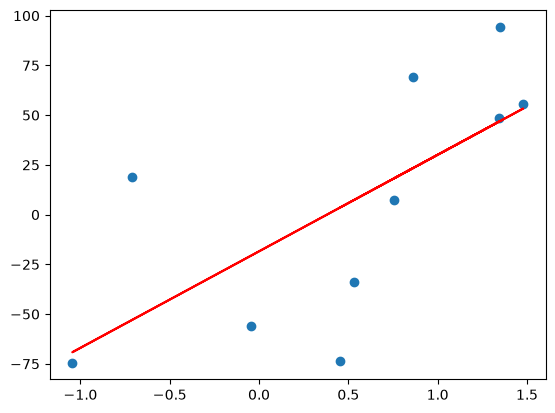

In [9]:
plt.scatter(X,y)
plt.plot(X,reg.predict(X),color='red')

### Step 10 — Make initial predictions

Use the fixed slope $m=78.35$ and starting intercept $b=0$ to calculate $\hat y_i=78.35x_i$. These predictions are the baseline before any gradient update.

In [10]:
y_pred = (78.35 * X).reshape(10)

### Step 11 — Compare the starting line with OLS

Plot the data, the OLS reference line, and the initial gradient-descent line with $b=0$. The difference between the two lines highlights the intercept error we will reduce.

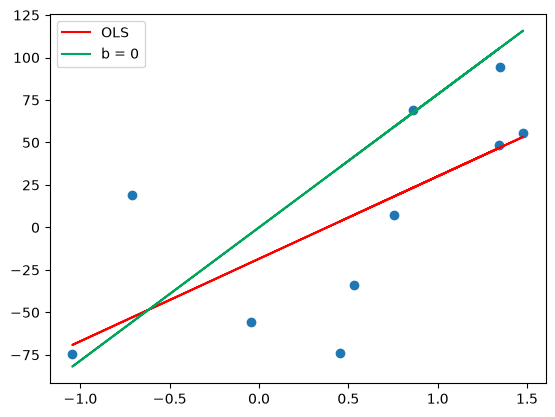

In [11]:
plt.scatter(X,y)
plt.plot(X,reg.predict(X),color='red',label='OLS')
plt.plot(X,y_pred,color='#00a65a',label='b = 0')
plt.legend()
plt.show()

### Step 12 — Calculate the initial MSE gradient

Set the fixed slope and initial intercept, then calculate $\partial J/\partial b=-(2/n)\sum_i(y_i-mx_i-b)$ for the MSE objective. This batch gradient uses every observation; its sign tells which direction to adjust $b$.

In [12]:
m = 78.35
b = 0.0

gradient_b = -(2 / len(y)) * np.sum(y - m * X.ravel() - b)
gradient_b

np.float64(66.54890097094554)

### Step 13 — Choose the learning rate and step size

Set $\eta=0.1$ and multiply it by the current gradient. The resulting step size is the amount that will be subtracted from the intercept; the learning rate controls how large that change is.

In [13]:
# Lets take learning rate = 0.1
lr = 0.1

step_size = gradient_b * lr
step_size

np.float64(6.654890097094555)

### Step 14 — Apply the first intercept update

Update the intercept with $b_{new}=b_{old}-\eta(\partial J/\partial b)$. Because the gradient can be negative, subtracting it may increase $b$; this moves the line toward lower MSE.

In [14]:
# Calculating the new intercept
b = b - step_size
b

np.float64(-6.654890097094555)

### Step 15 — Visualize the first update

Recompute predictions with the updated intercept and plot them beside the initial line and OLS reference. This lets us see the effect of one gradient-descent step.

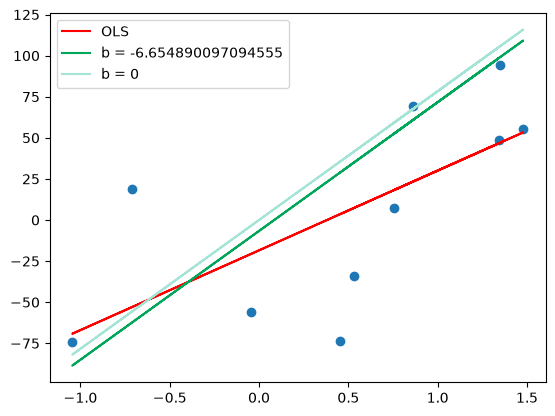

In [15]:
y_pred1 = ((78.35 * X) + b).reshape(10)

plt.scatter(X,y)
plt.plot(X,reg.predict(X),color='red',label='OLS')
plt.plot(X,y_pred1,color='#00a65a',label='b = {}'.format(b))
plt.plot(X,y_pred,color='#A3E4D7',label='b = 0')
plt.legend()
plt.show()

### Step 16 — Recalculate the gradient

Using the updated intercept, recompute the MSE derivative across all observations. The gradient changes after each update because the residuals have changed.

In [16]:
# Iteration 2
gradient_b = -(2 / len(y)) * np.sum(y - m * X.ravel() - b)
gradient_b

np.float64(53.23912077675644)

### Step 17 — Calculate the second step size

Multiply the newly calculated gradient by the same learning rate. The step size is recalculated at every iteration rather than reused from the first step.

In [17]:
step_size = gradient_b * lr
step_size

np.float64(5.323912077675644)

### Step 18 — Apply the second intercept update

Subtract the second step size from the current intercept. Repeating this update moves the parameter toward the minimum of the MSE objective.

In [18]:

b = b - step_size
b

np.float64(-11.978802174770198)

### Step 19 — Compare the second update

Calculate predictions after the second update and plot them along with the previous lines and the OLS reference. The visualization shows the sequence of intercept adjustments.

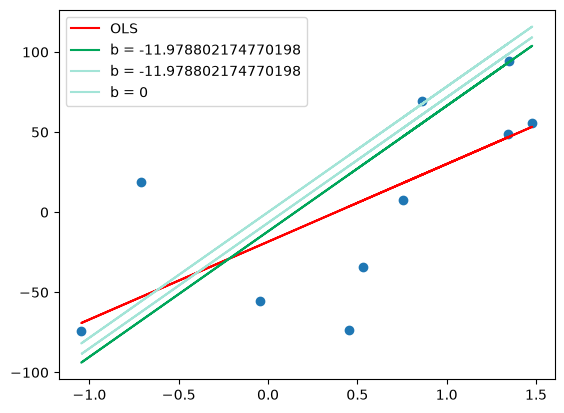

In [19]:

y_pred2 = ((78.35 * X) + b).reshape(10)

plt.scatter(X,y)
plt.plot(X,reg.predict(X),color='red',label='OLS')
plt.plot(X,y_pred2,color='#00a65a',label='b = {}'.format(b))
plt.plot(X,y_pred1,color='#A3E4D7',label='b = {}'.format(b))
plt.plot(X,y_pred,color='#A3E4D7',label='b = 0')
plt.legend()
plt.show()
     

### Step 20 — Run gradient descent for many iterations

Reset $b$ to $-100$ to demonstrate that optimization can start from a different value. For 100 epochs, this loop calculates the batch MSE gradient, updates $b$ using $\eta=0.01$, and plots each resulting line. The smaller learning rate makes the movement toward the minimum gradual.

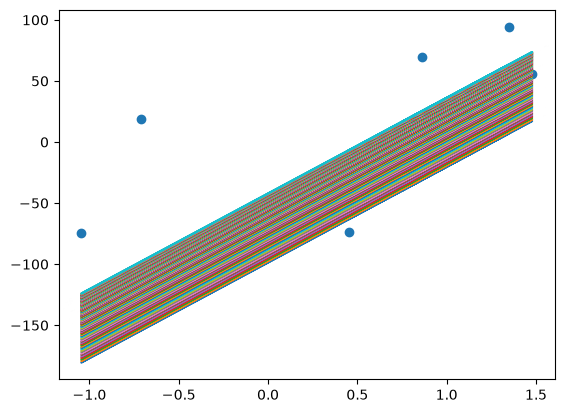

In [20]:
b = -100
m = 78.35
lr = 0.01

epochs = 100

for i in range(epochs):
  gradient_b = -(2 / len(y)) * np.sum(y - m * X.ravel() - b)
  b = b - (lr * gradient_b)

  y_pred = m * X + b

  plt.plot(X,y_pred)

plt.scatter(X,y)
plt.show()